In [10]:
!pip install -q langchain langchain-groq langgraph pydantic

In [36]:
import os
from google.colab import userdata
from langchain_groq import ChatGroq

groq_key2 = userdata.get("GROQ_KEY2")

if not groq_key2:
    raise ValueError("Add GROQ_KEY2 to Colab Secrets")

os.environ["GROQ_API_KEY"] = groq_key2

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.2,
    max_retries=3
)

print("Groq LLM ready")

Groq LLM ready


In [37]:
from langchain.tools import tool

ITEMS = {
    "notebook": 50,
    "pen": 10,
    "pencil": 5,
    "eraser": 5,
    "geometry box": 80,
    "file": 25,
    "marker": 20,
    "calculator": 350
}

HOURS = {
    "monday": "9 AM to 7 PM",
    "tuesday": "9 AM to 7 PM",
    "wednesday": "9 AM to 7 PM",
    "thursday": "9 AM to 7 PM",
    "friday": "9 AM to 7 PM",
    "saturday": "9 AM to 7 PM",
    "sunday": "10 AM to 2 PM"
}

orders = []

@tool
def get_price(item: str, quantity: int = 1) -> str:
    """Check stationery item price and total."""
    item = item.lower().strip()

    if item not in ITEMS:
        return "Item not found. Available: " + ", ".join(ITEMS)

    total = ITEMS[item] * quantity

    return f"{quantity} {item}(s), Rs {ITEMS[item]} each; total Rs {total}."

@tool
def check_stock(item: str) -> str:
    """Check whether an item is listed in inventory."""
    item = item.lower().strip()

    if item in ITEMS:
        return f"{item} is listed in inventory."

    available = ", ".join(ITEMS)
    return f"Not listed. Available: {available}."

@tool
def is_open(day: str) -> str:
    """Check store opening hours."""
    day = day.lower().strip()

    if day in HOURS:
        return f"{day}: {HOURS[day]}."

    return "Please provide a weekday."

@tool
def save_order(customer: str, item: str, quantity: int) -> str:
    """Save a confirmed stationery order."""
    item = item.lower().strip()

    if not customer.strip() or item not in ITEMS or quantity < 1:
        return "Order not saved. Check name, item and quantity."

    total = ITEMS[item] * quantity

    orders.append({
        "customer": customer.strip(),
        "item": item,
        "quantity": quantity,
        "total": total
    })

    return f"Saved {quantity} {item}(s). Total Rs {total}."

In [38]:
FAQS = {
    "delivery": "Home delivery within 3 km; delivery charge Rs 30.",
    "payment": "We accept cash and UPI.",
    "return": "Unused items can be returned within 7 days with the bill.",
    "exchange": "Exchange is allowed for unused items within 7 days.",
    "discount": "10% discount on purchases above Rs 1,000.",
    "bulk": "Bulk orders should be placed one day in advance.",
    "timing": "Monday-Saturday 9 AM-7 PM; Sunday 10 AM-2 PM.",
    "location": "The store is near the campus main gate.",
    "refund": "Eligible refunds are processed after checking the item and bill."
}

@tool
def search_faq(question: str) -> str:
    """Search store policies and frequently asked questions."""
    q = question.lower()

    keywords = {
        "delivery": ["deliver", "delivery", "home"],
        "payment": ["pay", "payment", "upi", "cash"],
        "return": ["return"],
        "exchange": ["exchange", "replace"],
        "discount": ["discount", "offer"],
        "bulk": ["bulk", "large order"],
        "timing": ["open", "hours", "timing", "close"],
        "location": ["where", "location", "address"],
        "refund": ["refund", "money back"]
    }

    found = []

    for key, words in keywords.items():
        if any(word in q for word in words):
            found.append(FAQS[key])

    if found:
        return "\n".join(found[:3])

    return "No matching policy found. Please ask store staff."

In [39]:
from langchain.agents import create_agent

FAQ_PROMPT = """
You are the Campus Stationery Store assistant.
Use search_faq for policies.
Use get_price for prices.
Use check_stock for stock.
Use is_open for timings.
Never invent facts.
If unknown, direct the customer to store staff.
Keep replies under 60 words.
"""

ORDER_PROMPT = """
You take stationery orders.
Use get_price and check_stock.
Before saving, confirm customer name, item and quantity.
Ask for missing details.
Save only complete orders.
Repeat the total to the customer.
Keep replies under 60 words.
"""

faq_agent = create_agent(
    model=llm,
    tools=[search_faq, get_price, check_stock, is_open],
    system_prompt=FAQ_PROMPT
)

order_agent = create_agent(
    model=llm,
    tools=[get_price, check_stock, save_order],
    system_prompt=ORDER_PROMPT
)

def ask_agent(agent, message):
    result = agent.invoke({
        "messages": [
            {"role": "user", "content": message}
        ]
    })

    answer = result["messages"][-1].content

    return answer if isinstance(answer, str) else str(answer)

In [40]:
from typing import Literal
from pydantic import BaseModel, Field

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order for purchase, faq for price or policy, other for greeting or unrelated"
    )

classifier = llm.with_structured_output(Intent)

def handle(message: str) -> str:
    intent = classifier.invoke(message).intent

    if intent == "order":
        return ask_agent(order_agent, message)

    if intent == "faq":
        return ask_agent(faq_agent, message)

    return "Welcome to Campus Stationery Store! I can help with items, prices, stock, orders and policies."

print(handle("How much do 3 notebooks cost?"))

Three notebooks cost Rs 150 total (Rs 50 each).


In [41]:
from typing_extensions import TypedDict

class StoreState(TypedDict):
    message: str
    intent: str
    reply: str

In [42]:
from langgraph.graph import StateGraph, START, END

def classify(state: StoreState) -> dict:
    result = classifier.invoke(state["message"])
    return {"intent": result.intent}

def answer_faq(state: StoreState) -> dict:
    return {
        "reply": ask_agent(faq_agent, state["message"])
    }

def take_order(state: StoreState) -> dict:
    return {
        "reply": ask_agent(order_agent, state["message"])
    }

def other(state: StoreState) -> dict:
    return {
        "reply": "Welcome to Campus Stationery Store! What item do you need?"
    }

def route(state: StoreState) -> str:
    return state["intent"]

builder = StateGraph(StoreState)

builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_node("order", take_order)
builder.add_node("other", other)

builder.add_edge(START, "classify")

builder.add_conditional_edges(
    "classify",
    route,
    {
        "order": "order",
        "faq": "faq",
        "other": "other"
    }
)

builder.add_edge("faq", END)
builder.add_edge("order", END)
builder.add_edge("other", END)

graph = builder.compile()

print("Graph compiled successfully")

Graph compiled successfully


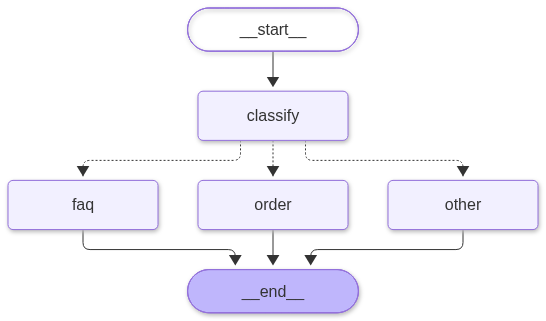

In [43]:
from IPython.display import Image, display

display(
    Image(graph.get_graph().draw_mermaid_png())
)

In [44]:
tests = [
    "Hello!",
    "How much do 4 pens cost?",
    "Do you have notebooks?",
    "What are Sunday hours?",
    "Do you deliver?",
    "I am Anu, order 2 geometry boxes."
]

for msg in tests:
    print("\nCustomer:", msg)

    try:
        result = graph.invoke({
            "message": msg,
            "intent": "",
            "reply": ""
        })

        print("Intent:", result["intent"])
        print("Assistant:", result["reply"])

    except Exception as e:
        print("Error:", e)


Customer: Hello!
Intent: other
Assistant: Welcome to Campus Stationery Store! What item do you need?

Customer: How much do 4 pens cost?
Intent: faq
Assistant: Four pens cost Rs 40 (Rs 10 each).

Customer: Do you have notebooks?
Intent: order
Assistant: Yes, we have notebooks. How many would you like, and may I have your name to complete the order?

Customer: What are Sunday hours?
Intent: faq
Assistant: Sunday: 10 AM – 2 PM.

Customer: Do you deliver?
Intent: faq
Assistant: Yes! We deliver to locations within 3 km of the store for a Rs 30 delivery charge. If you’re farther away, you can pick up your order at the store. Let us know what you’d like, and we’ll arrange it!

Customer: I am Anu, order 2 geometry boxes.
Intent: order
Assistant: Anu, would you like to order **geometry box** (singular) ? And is the quantity **2** correct?


In [45]:
print("Saved orders:")

for order in orders:
    print(order)

Saved orders:
